Dataset shape: (617667, 61)

--- SUMMARY STATISTICS ---
total_cases: mean=15,253,631.35, median=98,041.00, max=779,277,425.00
new_cases: mean=9,056.90, median=0.00, max=8,401,906.00
total_deaths: mean=162,304.35, median=1,196.00, max=7,115,706.00
new_deaths: mean=86.60, median=0.00, max=57,167.00
people_vaccinated: mean=259,413,512.98, median=6,977,072.00, max=5,645,247,500.00

Generating India daily cases plot...


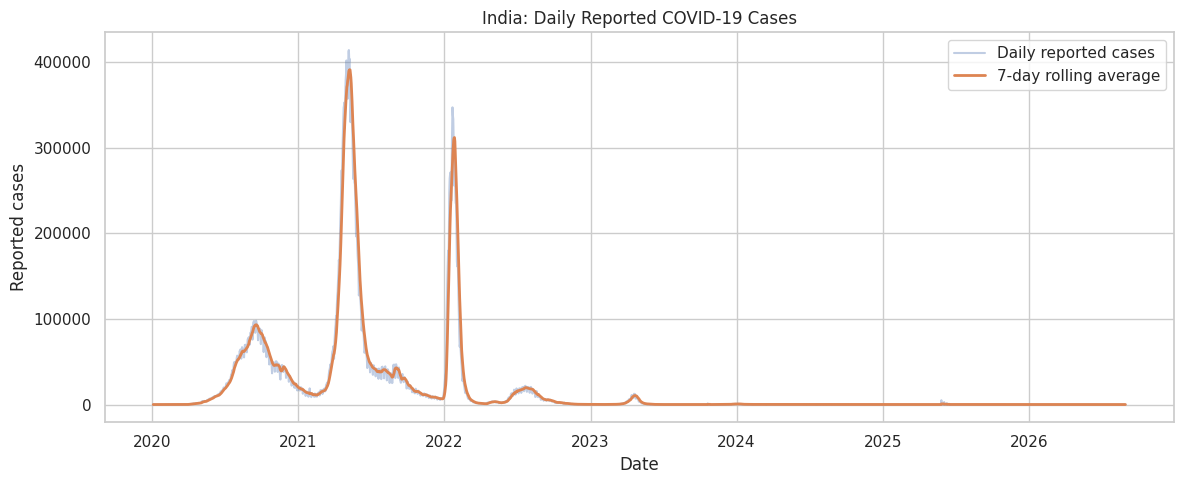


Generating Top 10 Countries plot...


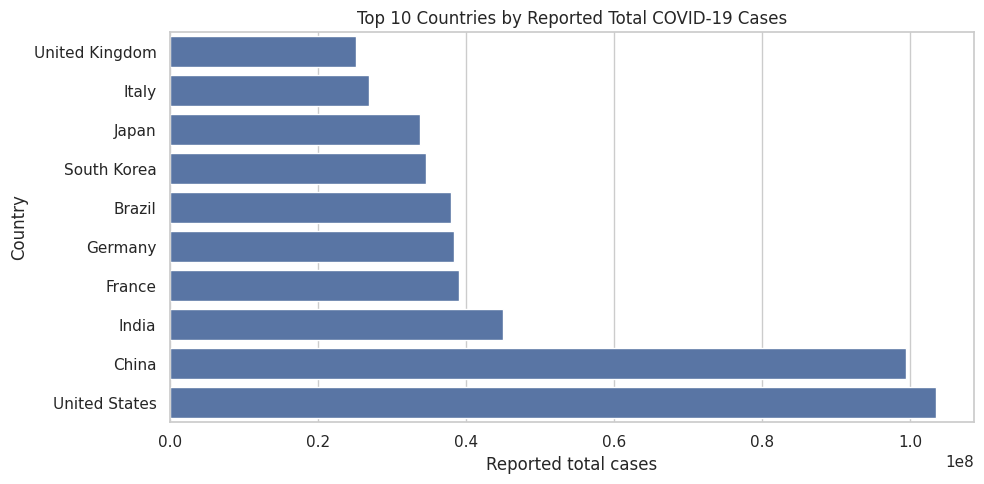


Generating Cases vs Deaths scatter plot...


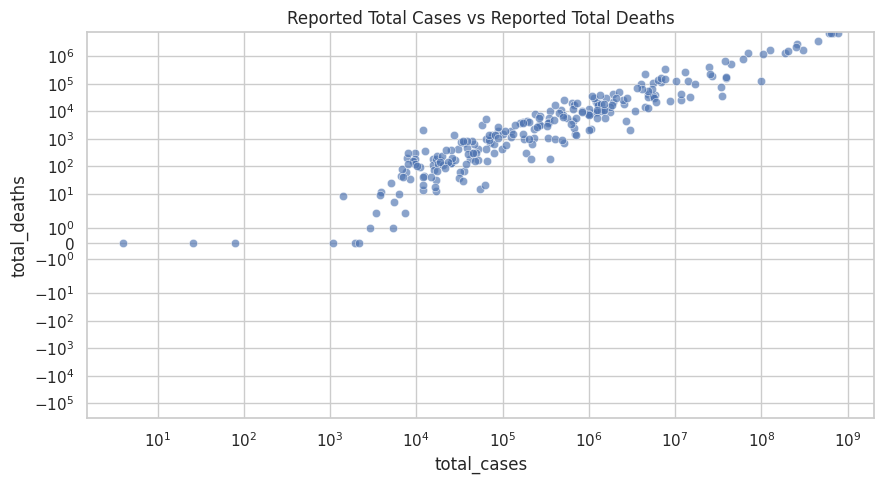

Correlation: 0.9838386294479887


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Setup and Load Data
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

DATA_URL = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"
df = pd.read_csv(DATA_URL, low_memory=False)
print("Dataset shape:", df.shape)

# 2. Basic Cleaning
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)

# 3. Display Summary Statistics
print("\n--- SUMMARY STATISTICS ---")
for col in ["total_cases", "new_cases", "total_deaths", "new_deaths", "people_vaccinated"]:
    if col in df.columns:
        values = pd.to_numeric(df[col], errors="coerce").dropna()
        if not values.empty:
            print(f"{col}: mean={values.mean():,.2f}, median={values.median():,.2f}, max={values.max():,.2f}")

# 4. Visualization: India Daily Cases
print("\nGenerating India daily cases plot...")
required_india = {"country", "date", "new_cases"}
if required_india.issubset(df.columns):
    india = df.loc[df["country"].astype(str).str.casefold().eq("india")].copy()
    india["new_cases"] = pd.to_numeric(india["new_cases"], errors="coerce")
    india = india.dropna(subset=["date"]).sort_values("date")
    india["new_cases_7day_avg"] = india["new_cases"].rolling(7, min_periods=1).mean()
    if not india.empty:
        plt.figure(figsize=(12, 5))
        plt.plot(india["date"], india["new_cases"], alpha=0.35, label="Daily reported cases")
        plt.plot(india["date"], india["new_cases_7day_avg"], linewidth=2, label="7-day rolling average")
        plt.title("India: Daily Reported COVID-19 Cases")
        plt.xlabel("Date")
        plt.ylabel("Reported cases")
        plt.legend()
        plt.tight_layout()
        plt.show()

# 5. Visualization: Country Comparison (Top 10)
print("\nGenerating Top 10 Countries plot...")
if {"country", "date", "total_cases"}.issubset(df.columns):
    country_data = df.copy()
    country_data["total_cases"] = pd.to_numeric(country_data["total_cases"], errors="coerce")
    country_data = country_data.dropna(subset=["date", "total_cases"])
    latest = country_data.sort_values("date").groupby("country", as_index=False).tail(1)
    latest = latest[~latest["country"].astype(str).str.contains("income|world|union|international|continent|europe|asia|north america|south america|africa|oceania", case=False, na=False)]
    top10 = latest.nlargest(10, "total_cases").sort_values("total_cases")
    plt.figure(figsize=(10, 5))
    sns.barplot(data=top10, x="total_cases", y="country")
    plt.title("Top 10 Countries by Reported Total COVID-19 Cases")
    plt.xlabel("Reported total cases")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()

# 6. Visualization: Cases vs Deaths Relationship
print("\nGenerating Cases vs Deaths scatter plot...")
if {"total_cases", "total_deaths"}.issubset(df.columns):
    relation = df[[c for c in ["country", "date", "total_cases", "total_deaths"] if c in df.columns]].copy()
    relation["total_cases"] = pd.to_numeric(relation["total_cases"], errors="coerce")
    relation["total_deaths"] = pd.to_numeric(relation["total_deaths"], errors="coerce")
    relation = relation.dropna(subset=["total_cases", "total_deaths"])
    if "date" in relation.columns:
        relation = relation.sort_values("date").groupby("country", as_index=False).tail(1)
    relation = relation[(relation["total_cases"] > 0) & (relation["total_deaths"] >= 0)]
    if len(relation) > 1:
        plt.figure(figsize=(9, 5))
        sns.scatterplot(data=relation, x="total_cases", y="total_deaths", alpha=0.65)
        plt.xscale("log")
        plt.yscale("symlog")
        plt.title("Reported Total Cases vs Reported Total Deaths")
        plt.tight_layout()
        plt.show()
        print("Correlation:", relation[["total_cases", "total_deaths"]].corr().iloc[0, 1])

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

DATA_URL = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"
df = pd.read_csv(DATA_URL, low_memory=False)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Dataset shape: (617667, 61)
Columns: ['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_boosters', 'new_vaccina

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN


In [3]:
print("Data types and non-null counts:")
df.info()

print("\nMissing values (top 15):")
display(df.isna().sum().sort_values(ascending=False).head(15))

print("Duplicate rows:", df.duplicated().sum())

if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)

print("\nPreview after basic cleaning:")
display(df.head())

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 617667 entries, 0 to 617666
Data columns (total 61 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   country                                     617667 non-null  object 
 1   date                                        617667 non-null  object 
 2   total_cases                                 605319 non-null  float64
 3   new_cases                                   600623 non-null  float64
 4   new_cases_smoothed                          599414 non-null  float64
 5   total_cases_per_million                     605319 non-null  float64
 6   new_cases_per_million                       600623 non-null  float64
 7   new_cases_smoothed_per_million              599414 non-null  float64
 8   total_deaths                                605319 non-null  float64
 9   new_deaths                            

,0
human_development_index,617667
weekly_icu_admissions,606674
weekly_icu_admissions_per_million,606674
excess_mortality_cumulative_per_million,603775
excess_mortality,603741
excess_mortality_cumulative,603741
excess_mortality_cumulative_absolute,603741
weekly_hosp_admissions_per_million,593170
weekly_hosp_admissions,593170
icu_patients,578551


Duplicate rows: 0

Preview after basic cleaning:


,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN


In [4]:
display(df.describe(include="all").T.head(20))

for col in ["total_cases", "new_cases", "total_deaths", "new_deaths", "people_vaccinated"]:
    if col in df.columns:
        values = pd.to_numeric(df[col], errors="coerce").dropna()
        if not values.empty:
            print(f"{col}: mean={values.mean():,.2f}, median={values.median():,.2f}, max={values.max():,.2f}")

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
country,617667,262,Zimbabwe,2434,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,617667,NaN,NaN,NaN,2023-04-22 11:33:58.855888128,2020-01-01 00:00:00,2021-08-25 00:00:00,2023-04-14 00:00:00,2024-12-18 00:00:00,2026-08-30 00:00:00,NaN
total_cases,605319.0,NaN,NaN,NaN,15253631.34932,0.0,11051.0,98041.0,1197082.0,779277425.0,77428001.616999
new_cases,600623.0,NaN,NaN,NaN,9056.902493,0.0,0.0,0.0,25.0,8401906.0,108826.852847
new_cases_smoothed,599414.0,NaN,NaN,NaN,9075.189464,0.0,0.0,1.571428,117.57143,6402033.0,92955.592202
total_cases_per_million,605319.0,NaN,NaN,NaN,140898.725384,0.0,4016.7324,59325.07,223640.14,769806.8,180852.078187
new_cases_per_million,600623.0,NaN,NaN,NaN,84.903229,0.0,0.0,0.0,2.551487,230762.55,907.958532
new_cases_smoothed_per_million,599414.0,NaN,NaN,NaN,85.077754,0.0,0.0,0.22879,19.131498,37463.746,468.484538
total_deaths,605319.0,NaN,NaN,NaN,162304.353703,0.0,89.0,1196.0,14122.0,7115706.0,802879.217131
new_deaths,601837.0,NaN,NaN,NaN,86.604016,0.0,0.0,0.0,0.0,57167.0,746.584457


total_cases: mean=15,253,631.35, median=98,041.00, max=779,277,425.00
new_cases: mean=9,056.90, median=0.00, max=8,401,906.00
total_deaths: mean=162,304.35, median=1,196.00, max=7,115,706.00
new_deaths: mean=86.60, median=0.00, max=57,167.00
people_vaccinated: mean=259,413,512.98, median=6,977,072.00, max=5,645,247,500.00


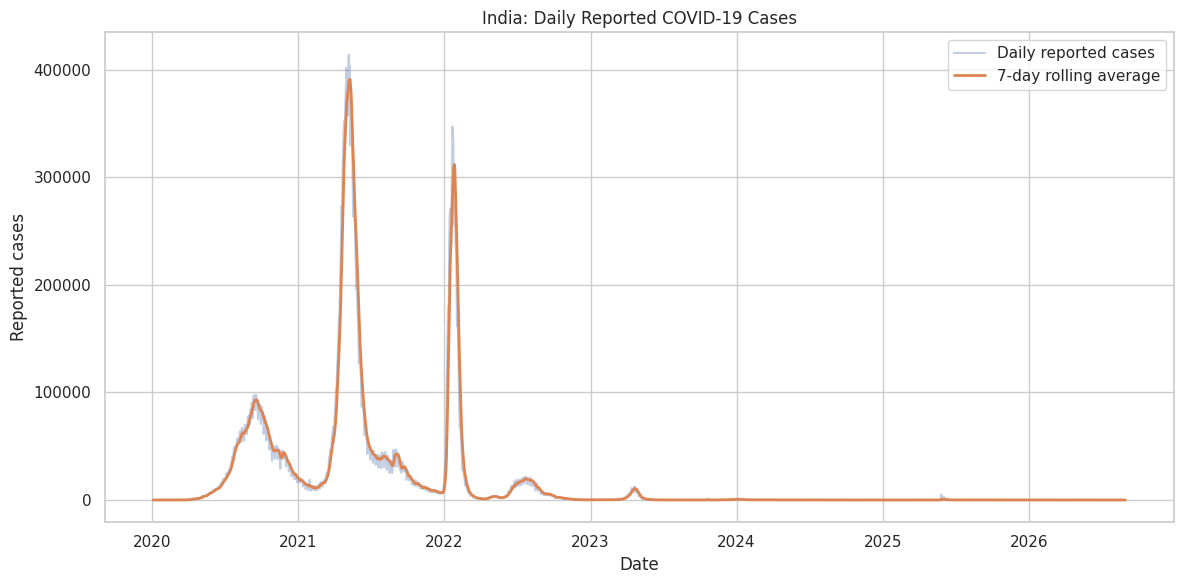

In [5]:
required = {"country", "date", "new_cases"}
if required.issubset(df.columns):
    india = df.loc[df["country"].astype(str).str.casefold().eq("india")].copy()
    india["new_cases"] = pd.to_numeric(india["new_cases"], errors="coerce")
    india = india.dropna(subset=["date"]).sort_values("date")
    india["new_cases_7day_avg"] = india["new_cases"].rolling(7, min_periods=1).mean()
    if not india.empty:
        fig, ax = plt.subplots()
        ax.plot(india["date"], india["new_cases"], alpha=0.35, label="Daily reported cases")
        ax.plot(india["date"], india["new_cases_7day_avg"], linewidth=2, label="7-day rolling average")
        ax.set(title="India: Daily Reported COVID-19 Cases", xlabel="Date", ylabel="Reported cases")
        ax.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("No India rows found in the current dataset.")
else:
    print("Required columns not available:", required - set(df.columns))

,country,date,total_cases
574769,United Kingdom,2026-08-30,25122084.0
267179,Italy,2026-08-30,26969918.0
272047,Japan,2026-08-30,33803572.0
514403,South Korea,2026-08-30,34571873.0
77863,Brazil,2026-08-30,38050567.0
204678,Germany,2026-08-30,38437953.0
190080,France,2026-08-30,39061500.0
250144,India,2026-08-30,45056221.0
111933,China,2026-08-30,99381761.0
577203,United States,2026-08-30,103436829.0


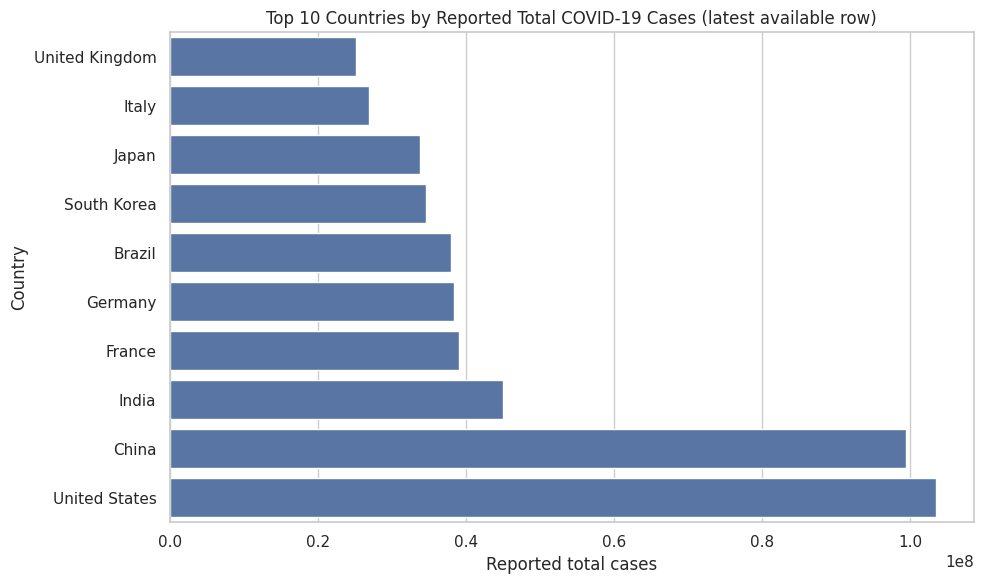

In [6]:
if {"country", "date", "total_cases"}.issubset(df.columns):
    country_data = df.copy()
    country_data["total_cases"] = pd.to_numeric(country_data["total_cases"], errors="coerce")
    country_data = country_data.dropna(subset=["date", "total_cases"])
    latest = country_data.sort_values("date").groupby("country", as_index=False).tail(1)
    # Filter out aggregated global/regional regions
    latest = latest[~latest["country"].astype(str).str.contains("income|world|union|international|continent|europe|asia|north america|south america|africa|oceania", case=False, na=False)]
    top10 = latest.nlargest(10, "total_cases").sort_values("total_cases")
    display(top10[["country", "date", "total_cases"]])
    plt.figure(figsize=(10, 6))
    sns.barplot(data=top10, x="total_cases", y="country")
    plt.title("Top 10 Countries by Reported Total COVID-19 Cases (latest available row)")
    plt.xlabel("Reported total cases")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not available for country comparison.")

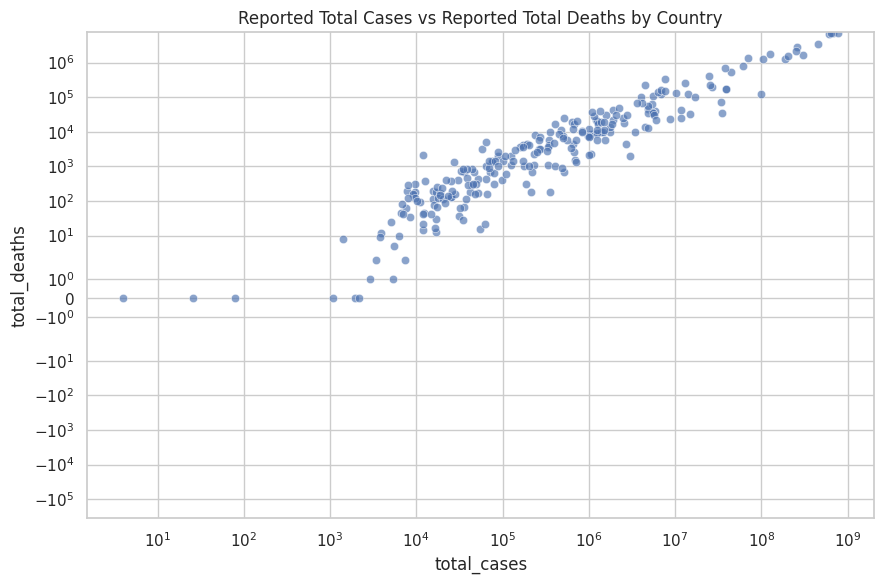

Correlation (latest available country totals): 0.9838386294479887


In [7]:
if {"total_cases", "total_deaths"}.issubset(df.columns):
    relation = df[[c for c in ["country", "date", "total_cases", "total_deaths"] if c in df.columns]].copy()
    relation["total_cases"] = pd.to_numeric(relation["total_cases"], errors="coerce")
    relation["total_deaths"] = pd.to_numeric(relation["total_deaths"], errors="coerce")
    relation = relation.dropna(subset=["total_cases", "total_deaths"])
    if "date" in relation.columns:
        relation = relation.sort_values("date").groupby("country", as_index=False).tail(1)
    relation = relation[(relation["total_cases"] > 0) & (relation["total_deaths"] >= 0)]
    if len(relation) > 1:
        plt.figure(figsize=(9, 6))
        sns.scatterplot(data=relation, x="total_cases", y="total_deaths", alpha=0.65)
        plt.xscale("log")
        plt.yscale("symlog")
        plt.title("Reported Total Cases vs Reported Total Deaths by Country")
        plt.tight_layout()
        plt.show()
        print("Correlation (latest available country totals):", relation[["total_cases", "total_deaths"]].corr().iloc[0, 1])
    else:
        print("Not enough rows for the relationship plot.")
else:
    print("Case/death columns are not available in this snapshot.")